## Import

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB


# nlp
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from nltk.tokenize import word_tokenize
import nltk
import string

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

import difflib
import random
import re
from typing import List

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


## Load the dataset

In [1]:
from google.colab import files
uploaded = files.upload()

Saving icthub_dataset.xlsx to icthub_dataset.xlsx


## Data Analysis

**Display dataset table**

In [5]:
df = pd.read_excel('/content/icthub_dataset.xlsx')
df.head()

,User Input,Category,Chatbot Response
0,Good morning,Greeting,Welcome to ICTHUB - For Digital Solutions! \n\...
1,Good afternoon,Greeting,Welcome to ICTHUB - For Digital Solutions! \n\...
2,Good evening,Greeting,Welcome to ICTHUB - For Digital Solutions! \n...
3,Hi there,Greeting,\n Welcome to ICTHUB - For Digital Solutions!...
4,Hello,Greeting,\n Welcome to ICTHUB - For Digital Solutions!...


**Display information dataset**

In [6]:
print(df.info(),"\n")
print("="*80)
print(df.describe(),"\n")
print("="*80)
print(df.isnull().sum(),"\n")
print("="*80)
print("Duplicated :",df.duplicated().sum(),"\n")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 715 entries, 0 to 714
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   User Input        715 non-null    object
 1   Category          715 non-null    object
 2   Chatbot Response  715 non-null    object
dtypes: object(3)
memory usage: 16.9+ KB
None 

                User Input                       Category  \
count                  715                            715   
unique                 711                             11   
top     You're a lifesaver  Asking for Internship Details   
freq                     2                             82   

                                         Chatbot Response  
count                                                 715  
unique                                                 36  
top     You are more than welcome! I'm very happy to a...  
freq                                                   64   

User Input

**Drop the duplication**

In [7]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [8]:
len(df['Category'].value_counts())

11

/tmp/ipykernel_1086/3105712324.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='Category', order=df['Category'].value_counts().index, palette='viridis')


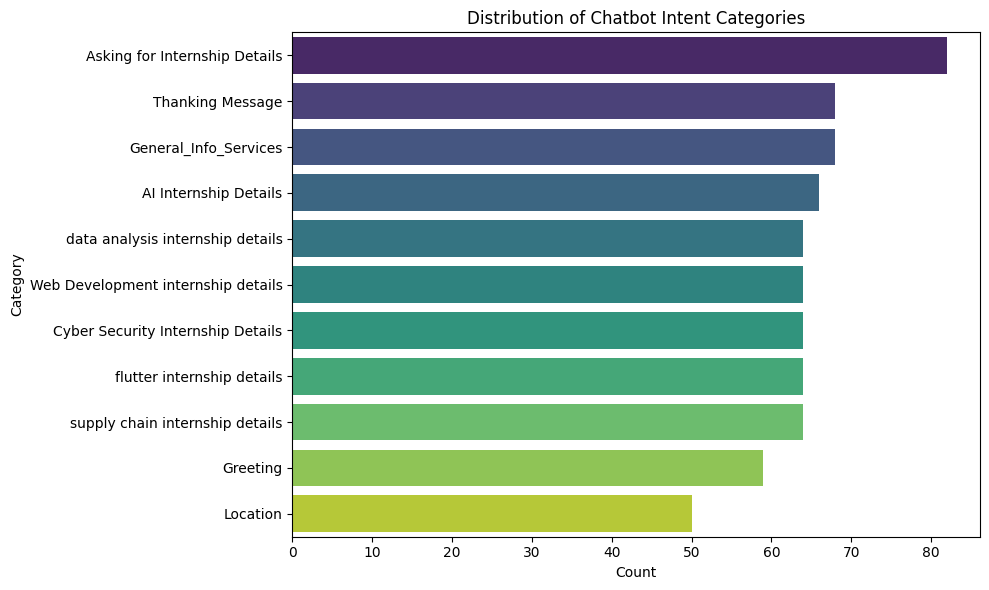

In [9]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='Category', order=df['Category'].value_counts().index, palette='viridis')
plt.title('Distribution of Chatbot Intent Categories')
plt.xlabel('Count')
plt.ylabel('Category')
plt.tight_layout()
plt.savefig('category_distribution.png')

In [11]:
df['input_length'] = df['User Input'].astype(str).apply(len)
df['input_length'].describe()

,input_length
count,713.000000
mean,49.963534
std,23.802826
min,2.000000
25%,33.000000
50%,51.000000
75%,68.000000
max,113.000000


## Data Preprocessing

###**Text Normalization and Cleaning:**

Convert all user inputs to lowercase to ensure uniformity. Remove punctuation, special characters, and extra whitespaces to reduce noise in the data and prevent the model from treating "Hello" and "hello!" as different words.

In [12]:
import re

# Assuming 'df' is your loaded dataset from 'icthub_dataset.xlsx'
def clean_text(text):
    # Convert to string to avoid errors with potential missing/float values
    text = str(text).lower()
    # Remove special characters and punctuation
    text = re.sub(r'[^\w\s]', '', text)
    # Remove extra whitespaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Apply the cleaning function to the User Input column
df['Cleaned_Input'] = df['User Input'].apply(clean_text)

# Verify the transformation
df[['User Input', 'Cleaned_Input']].head()

,User Input,Cleaned_Input
0,Good morning,good morning
1,Good afternoon,good afternoon
2,Good evening,good evening
3,Hi there,hi there
4,Hello,hello


###**Tokenization:**
Break down the cleaned text into individual tokens, which can be words or subwords. If you are building a custom sequence model, word-level tokenization is standard. If you opt for a transformer model, you will use its specific subword tokenizer.

In [13]:
# Initialize the stemmer and define the English stopwords set
stemmer = PorterStemmer()
stop_words = set(stopwords.words('english'))

def tokenize_process(text):
    # Break the string down into individual word tokens
    tokens = word_tokenize(str(text))

    # Filter out stopwords and punctuation, then apply stemming to reduce vocabulary size
    processed_tokens = [
        stemmer.stem(word) for word in tokens
        if word not in stop_words and word not in string.punctuation
    ]

    # Join back into a single string to prepare for TF-IDF vectorization
    return ' '.join(processed_tokens)

# Apply the tokenization and stemming pipeline
df['Tokenized_Input'] = df['Cleaned_Input'].apply(tokenize_process)

# Verify the tokenization output against the cleaned input
df[['Cleaned_Input', 'Tokenized_Input']].head()

,Cleaned_Input,Tokenized_Input
0,good morning,good morn
1,good afternoon,good afternoon
2,good evening,good even
3,hi there,hi
4,hello,hello


###**Target Variable Encoding:**
Your dataset contains 11 distinct intent categories. You must convert these categorical text labels into numerical values using label encoding (e.g., mapping "Greeting" to 0, "Location" to 1) so the neural network's loss function can compute errors during training.

In [14]:
# Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the encoder to the target column and transform the text labels into integers
df['Encoded_Category'] = label_encoder.fit_transform(df['Category'])

# Create a mapping dictionary to track which integer represents which category
# This is crucial for the deployment phase to translate the model's numerical prediction back into a recognizable intent
category_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))

print("--- Category to Integer Mapping ---")
for category, encoded_val in category_mapping.items():
    print(f"{encoded_val}: {category}")

# Verify the transformation alongside the original column
print("\n--- Encoded Target Variable ---")
df[['Category', 'Encoded_Category']].head(10)

--- Category to Integer Mapping ---
0: AI Internship Details
1: Asking for Internship Details
2: Cyber Security Internship Details
3: General_Info_Services
4: Greeting
5: Location
6: Thanking Message
7: Web Development internship details
8: data analysis internship details
9: flutter internship details
10: supply chain internship details

--- Encoded Target Variable ---


,Category,Encoded_Category
0,Greeting,4
1,Greeting,4
2,Greeting,4
3,Greeting,4
4,Greeting,4
5,Greeting,4
6,Greeting,4
7,Greeting,4
8,Greeting,4
9,Greeting,4


## Build models

In [15]:
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(df['Tokenized_Input']).toarray()
y = df['Encoded_Category'].values

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'SVC': SVC(kernel='linear'),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Multinomial NB': MultinomialNB()
}

In [19]:
results = {}
for name, model in models.items():
    print(f"Training {name} model...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[name] = accuracy_score(y_test, y_pred)

Training Logistic Regression model...
Training SVC model...
Training K-Nearest Neighbors model...
Training Random Forest model...
Training Multinomial NB model...


In [20]:
accuracy_scores = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {accuracy}")
    print("="*50)

Logistic Regression Accuracy: 0.993006993006993
SVC Accuracy: 0.993006993006993
K-Nearest Neighbors Accuracy: 0.7622377622377622
Random Forest Accuracy: 0.972027972027972
Multinomial NB Accuracy: 0.9790209790209791


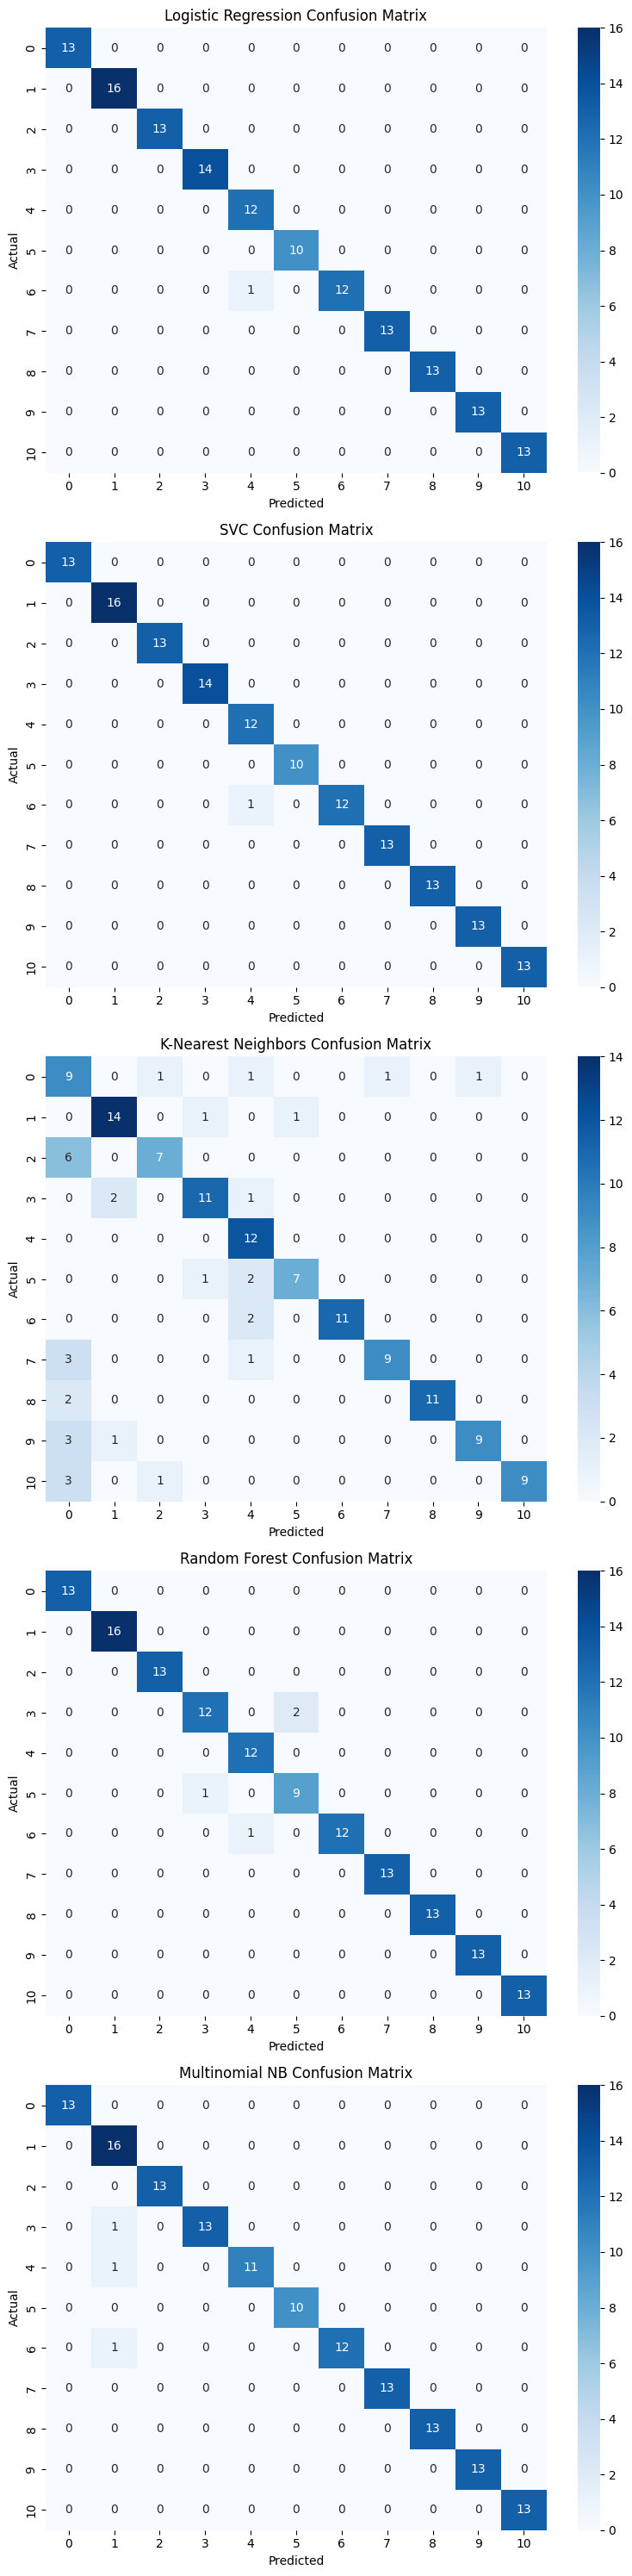

In [23]:
# Create confusion matrices for each model arranged vertically
fig, axes = plt.subplots(len(models), 1, figsize=(8, 6 * len(models)))

for idx, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    # Plot confusion matrix on the corresponding vertical axis
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx])
    axes[idx].set_title(f'{name} Confusion Matrix')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

plt.tight_layout()
plt.show()

----------------------------------------
🏆 BEST MODEL: Logistic Regression
🔥 HIGHEST ACCURACY: 99.30%
----------------------------------------


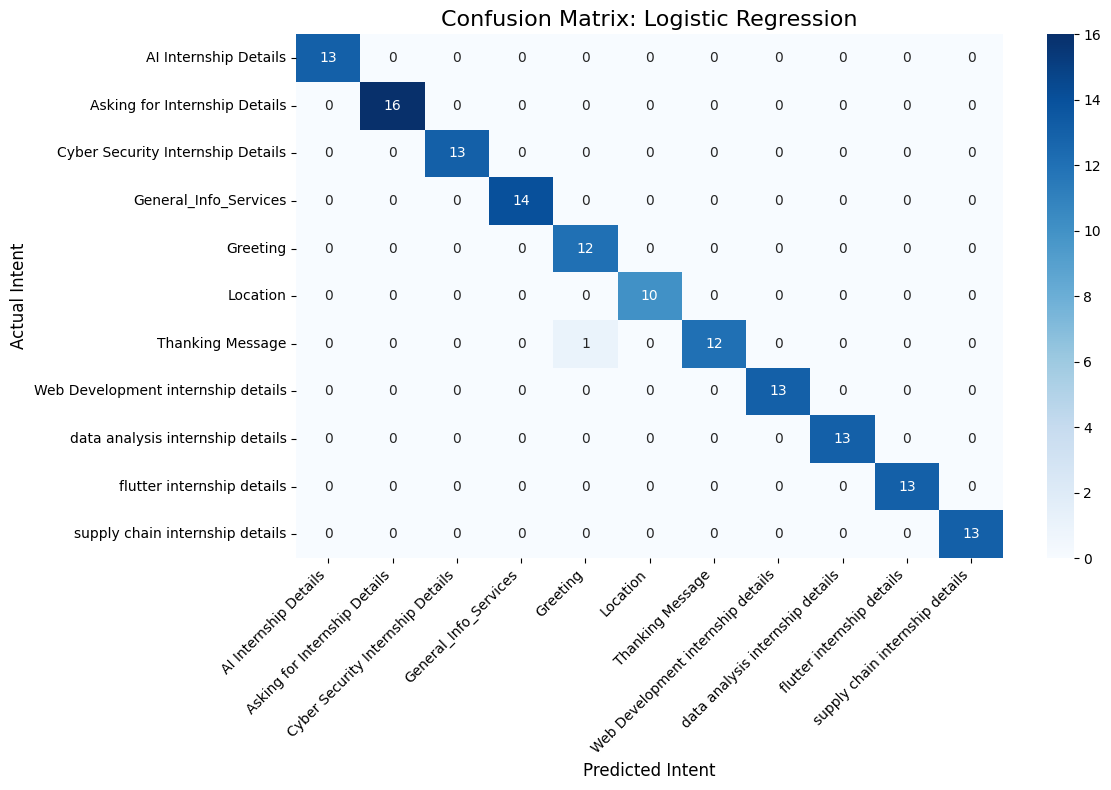

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Identify the best model and its accuracy from the previous results
best_model_name = max(results, key=results.get)
highest_accuracy = results[best_model_name]
best_model = models[best_model_name]

print("-" * 40)
print(f"🏆 BEST MODEL: {best_model_name}")
print(f"🔥 HIGHEST ACCURACY: {highest_accuracy * 100:.2f}%")
print("-" * 40)

# Get predictions for the best model
y_pred_best = best_model.predict(X_test)

# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred_best)

# Plotting
plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title(f'Confusion Matrix: {best_model_name}', fontsize=16)
plt.xlabel('Predicted Intent', fontsize=12)
plt.ylabel('Actual Intent', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Deployment

In [27]:
# Assuming tfidf is your fitted TfidfVectorizer
known_words: List[str] = list(tfidf.vocabulary_.keys())

def is_similar_to_known_words(user_input: str, min_matches: int = 1) -> bool:
    """
    Evaluates if user input contains a minimum number of words similar to the known TF-IDF vocabulary.

    Args:
        user_input (str): The raw text input from the user.
        min_matches (int): Minimum number of matched words required to return True.

    Returns:
        bool: True if the match count meets or exceeds min_matches, False otherwise.
    """
    # 1. Normalize the input: lowercase and strip punctuation to align with TF-IDF token format
    clean_input = re.sub(r'[^\w\s]', '', str(user_input).lower())
    words = clean_input.split()

    match_count = 0
    for word in words:
        # 2. difflib is computationally expensive; keep n=1 for maximum speed
        close = difflib.get_close_matches(word, known_words, n=1, cutoff=0.75)

        if close:
            match_count += 1

        # 3. Early Stopping: Exit the loop immediately once the threshold is met
        # This prevents unnecessary iterations over remaining words, reducing latency.
        if match_count >= min_matches:
            return True

    return False

In [28]:
import random
from typing import Dict, List

# 1. Precompute the response mapping dictionary ONCE outside the function
# This achieves O(1) latency during live inference
intent_responses: Dict[str, List[str]] = df.groupby('Category')['Chatbot Response'].apply(list).to_dict()

def chatbot_response(user_input: str) -> str:
    """
    Processes raw user input through the NLP pipeline, predicts the intent,
    and returns a randomized appropriate response.
    """
    try:
        # 2. Execute the preprocessing pipeline
        cleaned_text = clean_text(user_input)
        tokenized_text = tokenize_process(cleaned_text)

        # 3. Handle Out-Of-Vocabulary (OOV) inputs to prevent hallucination or crashes
        if not is_similar_to_known_words(tokenized_text, min_matches=1):
            return "Chatbot: Sorry, I didn't quite catch that. Could you rephrase?"

        # 4. Transform text to numerical features using the fitted TF-IDF Vectorizer
        vectorized_input = tfidf.transform([tokenized_text]).toarray()

        # 5. Predict the class using your best performing model (e.g., Logistic Regression / SVC)
        predicted_encoded = best_model.predict(vectorized_input)
        predicted_category = label_encoder.inverse_transform(predicted_encoded)[0]

        # 6. Map the predicted intent to a response
        possible_responses = intent_responses.get(predicted_category, [])

        if possible_responses:
            final_response = random.choice(possible_responses).strip()
            return f"Chatbot: {final_response}"
        else:
            return "Chatbot: Sorry, I don't have information on that topic right now."

    except Exception as e:
        # Failsafe for unexpected pipeline errors
        return "Chatbot: I'm experiencing a technical issue processing your request."

In [39]:
import gradio as gr
import os, time, base64, inspect

# ------------------------------------------------------------------
# Assumes chatbot_response(user_input: str) -> str is defined earlier
# ------------------------------------------------------------------

image_path = '/content/images.png'
GRADIO_MAJOR = int(gr.__version__.split(".")[0])

# ---- Logo as plain HTML (no fullscreen / download / share buttons) ----
if os.path.exists(image_path):
    with open(image_path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode()
    logo_html = f'<img src="data:image/png;base64,{b64}" class="logo-img">'
else:
    logo_html = '<div class="logo-img logo-fallback">IH</div>'

HEADER_HTML = f"""
<div class="wa-header">
  {logo_html}
  <div class="wa-text">
    <div class="wa-name">ICTHUB Digital Solutions</div>
    <div class="wa-status">● online</div>
  </div>
</div>
"""

CSS = """
/* ---------- Force light look everywhere ---------- */
:root, .dark, .gradio-container, .gradio-container.dark {
    --body-background-fill: #e5ddd5 !important;
    --background-fill-primary: #ffffff !important;
    --background-fill-secondary: #f0f2f5 !important;
    --block-background-fill: transparent !important;
    --body-text-color: #111b21 !important;
    --block-border-color: transparent !important;
    --input-background-fill: #ffffff !important;
    --input-border-color: transparent !important;
    --border-color-primary: transparent !important;
}
body, .gradio-container {
    background: #e5ddd5 !important;
    color: #111b21 !important;
}
.gradio-container {
    max-width: 760px !important;
    margin: 20px auto !important;
    padding: 0 !important;
    border-radius: 14px;
    overflow: hidden;
    box-shadow: 0 6px 24px rgba(0,0,0,.18);
}
.gradio-container .block, .gradio-container .form, .gradio-container .row {
    border: none !important;
    box-shadow: none !important;
    gap: 0 !important;
    padding: 0 !important;
}
footer { display: none !important; }

/* ---------- Header ---------- */
.wa-header {
    display: flex; align-items: center; gap: 14px;
    background: #075E54; padding: 12px 18px;
}
.logo-img {
    width: 48px; height: 48px; border-radius: 50%;
    object-fit: cover; background: #fff; flex: 0 0 48px;
}
.logo-fallback {
    display:flex; align-items:center; justify-content:center;
    font-weight:700; color:#075E54;
}
.wa-name   { color: #fff; font-size: 17px; font-weight: 600; line-height: 1.2; }
.wa-status { color: #7ee2c3; font-size: 12px; margin-top: 2px; }

/* ---------- Chat area ---------- */
#chatbox {
    background: #efeae2 !important;
    background-image: radial-gradient(#d8d0c3 1px, transparent 1px) !important;
    background-size: 20px 20px !important;
    border: none !important;
    border-radius: 0 !important;
}
#chatbox, #chatbox * { color: #111b21; }

/* every message: ONE clean bubble */
#chatbox .message {
    border: none !important;
    border-radius: 10px !important;
    padding: 7px 12px !important;
    font-size: 15px !important;
    line-height: 1.45 !important;
    box-shadow: 0 1px 1px rgba(0,0,0,.15) !important;
    width: fit-content !important;
    max-width: 80% !important;
    min-width: 0 !important;
    background: #ffffff !important;
}
/* kill the inner box that created the "bubble inside bubble" */
#chatbox .message *,
#chatbox .message .prose,
#chatbox .message-content,
#chatbox .message p {
    background: transparent !important;
    border: none !important;
    box-shadow: none !important;
    color: #111b21 !important;
    margin: 0 0 4px 0 !important;
    padding: 0 !important;
}
#chatbox .message p:last-child { margin-bottom: 0 !important; }

#chatbox .message.user, #chatbox .user .message, #chatbox .message-row.user-row .message {
    background: #d9fdd3 !important;
    border-top-right-radius: 2px !important;
}
#chatbox .message.bot, #chatbox .bot .message, #chatbox .message-row.bot-row .message {
    background: #ffffff !important;
    border-top-left-radius: 2px !important;
}

/* hide share / trash / copy / undo icons on messages and chat */
#chatbox .icon-button-wrapper,
#chatbox .message-buttons,
#chatbox .message-buttons-left,
#chatbox .message-buttons-right,
#chatbox button[aria-label="Share"],
#chatbox button[aria-label="Clear"],
#chatbox button[aria-label="Copy"],
#chatbox button[aria-label="Copy message"],
#chatbox button[aria-label="Copy conversation"],
#chatbox button[title="Share"],
#chatbox button[title="Clear"],
#chatbox button[title="Copy"] { display: none !important; }

/* ---------- Quick replies ---------- */
#chips {
    background: #efeae2 !important;
    padding: 8px 12px !important;
    gap: 8px !important;
    flex-wrap: wrap !important;
}
#chips button {
    background: #ffffff !important;
    color: #075E54 !important;
    border: 1px solid #cfe3de !important;
    border-radius: 18px !important;
    font-size: 13px !important;
    font-weight: 600 !important;
    padding: 5px 14px !important;
    min-width: 0 !important;
    flex: 0 0 auto !important;
    box-shadow: 0 1px 1px rgba(0,0,0,.08) !important;
}
#chips button:hover { background: #e7f6f3 !important; }

/* ---------- Input bar ---------- */
#input-bar {
    background: #f0f2f5 !important;
    padding: 10px 12px !important;
    gap: 8px !important;
    align-items: center !important;
    flex-wrap: nowrap !important;
}
#msg-box, #msg-box > *, #msg-box label, #msg-box div {
    background: transparent !important;
    border: none !important;
    box-shadow: none !important;
    padding: 0 !important;
}
#msg-box textarea {
    background: #ffffff !important;
    color: #111b21 !important;
    border: none !important;
    border-radius: 22px !important;
    padding: 12px 18px !important;
    box-shadow: none !important;
    font-size: 15px !important;
}
#msg-box textarea::placeholder { color: #8696a0 !important; }

#send-btn {
    background: #00a884 !important;
    color: #fff !important;
    border: none !important;
    border-radius: 50% !important;
    min-width: 46px !important; max-width: 46px !important;
    height: 46px !important;
    font-size: 18px !important;
    padding: 0 !important;
    flex: 0 0 46px !important;
}
#send-btn:hover { background: #029477 !important; }
#clear-btn {
    background: transparent !important;
    border: none !important;
    box-shadow: none !important;
    min-width: 42px !important; max-width: 42px !important;
    flex: 0 0 42px !important;
    font-size: 18px !important;
    padding: 0 !important;
}
"""

# Force light mode in the browser (Gradio follows the OS dark setting otherwise)
FORCE_LIGHT_JS = """
() => {
  const apply = () => {
    document.documentElement.classList.remove('dark');
    document.body.classList.remove('dark');
  };
  apply();
  setInterval(apply, 500);
}
"""

WELCOME = [{"role": "assistant",
            "content": "👋 Hello! Welcome to **ICTHUB Digital Solutions**.\n\nAsk me anything about our digital services and internships."}]

def clean(text: str) -> str:
    text = str(text).strip()
    if text.lower().startswith("chatbot:"):
        text = text[len("chatbot:"):].strip()
    return text

# ---------------------- Chat logic ------------------------
def respond(user_input, history):
    history = history or []
    if not user_input or not user_input.strip():
        yield history, ""
        return

    history = history + [{"role": "user", "content": user_input}]
    yield history, ""

    history = history + [{"role": "assistant", "content": "✍️ *typing...*"}]
    yield history, ""

    try:
        answer = clean(chatbot_response(user_input))
    except Exception as e:
        answer = f"⚠️ Sorry, something went wrong: {e}"

    shown = ""
    for word in answer.split(" "):
        shown += word + " "
        history[-1] = {"role": "assistant", "content": shown}
        yield history, ""
        time.sleep(0.025)

def quick(text):
    def _fn(history):
        yield from respond(text, history)
    return _fn

def clear_chat():
    return WELCOME.copy()

# ---------------------- Build UI ------------------------
theme = gr.themes.Soft(primary_hue="green")
blocks_kwargs, launch_kwargs = {}, dict(share=True, debug=True)
if GRADIO_MAJOR >= 6:
    launch_kwargs.update(theme=theme, css=CSS)
else:
    blocks_kwargs.update(theme=theme, css=CSS)

# Chatbot options that differ between versions: only pass what exists
cb_params = inspect.signature(gr.Chatbot.__init__).parameters
chatbot_kwargs = dict(value=WELCOME, elem_id="chatbox", height=470, show_label=False)
if "type" in cb_params:               chatbot_kwargs["type"] = "messages"
if "show_copy_button" in cb_params:   chatbot_kwargs["show_copy_button"] = False
if "show_share_button" in cb_params:  chatbot_kwargs["show_share_button"] = False
if "show_copy_all_button" in cb_params: chatbot_kwargs["show_copy_all_button"] = False
if "buttons" in cb_params:            chatbot_kwargs["buttons"] = []
if "layout" in cb_params:             chatbot_kwargs["layout"] = "bubble"

with gr.Blocks(title="ICTHUB Assistant", **blocks_kwargs) as iface:
    gr.HTML(HEADER_HTML)
    chatbot = gr.Chatbot(**chatbot_kwargs)

    with gr.Row(elem_id="chips"):
        chip1 = gr.Button("🎓 Internships")
        chip2 = gr.Button("💻 Digital services")
        chip3 = gr.Button("📍 Contact info")

    with gr.Row(elem_id="input-bar"):
        clear_btn = gr.Button("🗑️", elem_id="clear-btn")
        msg = gr.Textbox(placeholder="Type a message", show_label=False,
                         container=False, lines=1, max_lines=4, scale=8, elem_id="msg-box")
        send_btn = gr.Button("➤", elem_id="send-btn")

    msg.submit(respond, [msg, chatbot], [chatbot, msg])
    send_btn.click(respond, [msg, chatbot], [chatbot, msg])

    chip1.click(quick("Tell me about internships"), chatbot, [chatbot, msg])
    chip2.click(quick("What digital services do you offer?"), chatbot, [chatbot, msg])
    chip3.click(quick("How can I contact you?"), chatbot, [chatbot, msg])
    clear_btn.click(clear_chat, None, chatbot)

    iface.load(None, None, None, js=FORCE_LIGHT_JS)

iface.queue().launch(**launch_kwargs)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://1367bc66215d662993.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://1367bc66215d662993.gradio.live
